# Лабораторная работа № 3
## Классическое выравнивание и N-граммные языковые модели

Цель работы - разобраться, как выбирается путь по акустическим состояниям с помощью алгоритма Витерби, как биграммная языковая модель оценивает предложения и почему вес языковой модели может менять выбор гипотезы

## 0. Подготовка

Использую исходные скрипты из задания и дополняю пропущенное в `viterbi_alignment.py`, `bigram_lm.py` и `combine_candidate_scores.py`

In [2]:
from pathlib import Path
import csv
import json
import math
import subprocess
import sys
from collections import Counter
from IPython.display import display, SVG, Markdown

# Notebook сохраняю в корне lab_03, поэтому все пути задаю относительно него
ROOT = Path.cwd()
if not (ROOT / "scripts" / "run_lab_03.py").exists():
    raise FileNotFoundError("Откройте notebook из корня lab_03")
SCRIPTS = ROOT / "scripts"
DATA = ROOT / "data"
OUT = ROOT / "outputs"

print("Python:", sys.version.split()[0])
print("Папка проекта:", ROOT)

Python: 3.11.17
Папка проекта: d:\МАГА\2 курс\ASR\lab_03_ru


## 1. Проверка файлов и схема программы

Общий порядок работы: `run_lab_03.py` читает матрицу стоимостей, корпус и кандидатов, вызывает три модуля и сохраняет график и таблицы в `outputs/`

In [ ]:
required = [
    SCRIPTS / "run_lab_03.py",
    SCRIPTS / "viterbi_alignment.py",
    SCRIPTS / "bigram_lm.py",
    SCRIPTS / "combine_candidate_scores.py",
    DATA / "toy_alignment_costs.json",
    DATA / "toy_lm_corpus.txt",
    DATA / "toy_candidate_scores.json",
]

for path in required:
    print(("OK" if path.exists() else "НЕТ"), path.relative_to(ROOT))
    
assert all(path.exists() for path in required)

OK scripts\run_lab_03.py
OK scripts\viterbi_alignment.py
OK scripts\bigram_lm.py
OK scripts\combine_candidate_scores.py
OK data\toy_alignment_costs.json
OK data\toy_lm_corpus.txt
OK data\toy_candidate_scores.json


| Функция | Что получает | Что возвращает |
|---|---|---|
| `viterbi_align` | Матрицу стоимостей и индексы начального/конечного состояний | Последовательность индексов и итоговую стоимость |
| `BigramLM.train` | Строки корпуса и `k=0.5` | Модель с частотами биграмм и контекстов |
| `bigram_probability` | Предыдущее и следующее слово | Условную вероятность следующего слова |
| `sentence_logprob` | Текст гипотезы | Сумму десятичных логарифмов биграмм |
| `rank_candidates` | Гипотезы и вес LM | Гипотезы по убыванию объединённой оценки |

## 2. Часть A. Алгоритм Витерби

В слове `yes` выделено пять последовательных состояний: `sil_start`, `/y/`, `/e/`, `/s/`, `sil_end`

Для каждого кадра задана стоимость эмиссии. Меньшая стоимость означает более подходящее состояние для этого кадра, но выбирать минимальную ячейку в каждом столбце отдельно нельзя, потому что путь должен сохранять порядок состояний

На следующем кадре разрешено остаться в том же состоянии или перейти на одно состояние вперёд, поэтому для накопленной стоимости использую рекуррентную формулу

$$D[t,s] = E[t,s] + \min(D[t-1,s], D[t-1,s-1])$$

`dp` хранит минимальную накопленную стоимость, а `back` - индекс предыдущего состояния, чтобы после вычислений восстановить путь с конца

In [ ]:
alignment = json.loads((DATA / "toy_alignment_costs.json").read_text(encoding="utf-8"))
state_labels = alignment["state_labels"]
frame_labels = alignment["frame_labels"]

costs = alignment["costs"]

print("Кадры:", frame_labels)
print("Состояния:", state_labels)
print("Матрица стоимостей (строки - кадры):")
print("кадр  " + "  ".join(f"{name:>9}" for name in state_labels))

for label, values in zip(frame_labels, costs):
    print(f"{label:<5} " + "  ".join(f"{v:9.1f}" for v in values))

Кадры: ['f1', 'f2', 'f3', 'f4', 'f5', 'f6']
Состояния: ['sil_start', '/y/', '/e/', '/s/', 'sil_end']
Матрица стоимостей (строки - кадры):
кадр  sil_start        /y/        /e/        /s/    sil_end
f1          0.4        9.0        9.0        9.0        9.0
f2          9.0        0.7        9.0        9.0        9.0
f3          9.0        0.5        1.2        9.0        9.0
f4          9.0        9.0        0.6        9.0        9.0
f5          9.0        9.0        9.0        0.5        9.0
f6          9.0        9.0        9.0        9.0        0.3


### Какие вычисления дописаны

В `viterbi_alignment.py` сначала добавляю вариант остаться в текущем состоянии, затем, если это допустимо, переход из предыдущего состояния

`min` выбирает вариант с меньшей накопленной стоимостью. Если стоимости равны, он оставляет первый вариант, то есть сохранение состояния

После выбора прибавляю стоимость эмиссии и запоминаю предыдущее состояние в `back`. Для недостижимых ячеек стоимость остаётся бесконечной

In [ ]:
from scripts.viterbi_alignment import viterbi_align

path, total_cost = viterbi_align(costs, start_state=0, final_state=len(state_labels)-1)
path_labels = [state_labels[index] for index in path]

print("Лучший путь:", " -> ".join(path_labels))
print(f"Общая стоимость: {total_cost:.1f}")
print("Альтернатива:", [state_labels[i] for i in alignment["known_alternative"]["path"]])
print(f"Стоимость альтернативы: {alignment['known_alternative']['total_cost']:.1f}")

Лучший путь: sil_start -> /y/ -> /y/ -> /e/ -> /s/ -> sil_end
Общая стоимость: 3.0
Альтернатива: ['sil_start', '/y/', '/e/', '/e/', '/s/', 'sil_end']
Стоимость альтернативы: 3.7


### Накопленная стоимость по кадрам

Посчитаю её отдельно по найденному пути, чтобы увидеть, из каких слагаемых получилась итоговая стоимость 3.0

In [ ]:
cumulative = 0.0
print(f"{'Кадр':<7} {'Состояние':<12} {'Эмиссия':>8} {'Сумма':>8}")

for t, state in enumerate(path):
    emission = costs[t][state]
    cumulative += emission
    print(f"{frame_labels[t]:<7} {state_labels[state]:<12} {emission:>8.1f} {cumulative:>8.1f}")
    
assert path == [0, 1, 1, 2, 3, 4]
assert math.isclose(total_cost, 3.0)

Кадр    Состояние     Эмиссия    Сумма
f1      sil_start         0.4      0.4
f2      /y/               0.7      1.1
f3      /y/               0.5      1.6
f4      /e/               0.6      2.2
f5      /s/               0.5      2.7
f6      sil_end           0.3      3.0


**Вывод по выравниванию**

Лучший путь: `sil_start -> /y/ -> /y/ -> /e/ -> /s/ -> sil_end`, стоимость 3.0 против 3.7 у альтернативного пути

На кадрах `f2` и `f3` состояние `/y/` сохраняется, остальные переходы продвигаются на одно состояние вперёд. Два пути удовлетворяют ограничениям, но сумма стоимостей у первого ниже на 0.7

## 3. Часть B. Биграммная языковая модель

Модель обучается на семи предложениях и учитывает частоту пары слов $C(h,w)$, частоту предыдущего слова $C(h)$ и размер словаря $|V|$

Без сглаживания незнакомая биграмма имела бы вероятность 0, поэтому использую add-k с `k=0.5`

$$P(w\mid h)=\frac{C(h,w)+k}{C(h)+k|V|}$$

`<s>` обозначает начало предложения и используется только как контекст, `</s>` считается следующим токеном, а неизвестные слова заменяются на `<unk>`

In [ ]:
from scripts.bigram_lm import BigramLM, BOS, EOS, UNK, tokenize

corpus = (DATA / "toy_lm_corpus.txt").read_text(encoding="utf-8").splitlines()
lm = BigramLM.train(corpus, k=0.5)

print("Предложений:", len(corpus))
print("Словарь:", ", ".join(sorted(lm.vocabulary)))
print("Размер словаря:", len(lm.vocabulary))
print("Контекст drink:", lm.context_counts["drink"])

for word in ["green", "strong", "tea", UNK]:
    print(f"C(drink, {word}) = {lm.bigram_counts[('drink', word)]}")

Предложений: 7
Словарь: </s>, <unk>, coffee, drink, green, like, strong, tea, they, we
Размер словаря: 10
Контекст drink: 4
C(drink, green) = 3
C(drink, strong) = 1
C(drink, tea) = 0
C(drink, <unk>) = 0


### Ручная проверка одной биграммы

В корпусе `drink` встречается 4 раза, `drink green` - 3 раза, а размер словаря предсказываемых токенов равен 10

$$P(\text{green}\mid\text{drink}) = \frac{3+0.5}{4+0.5\cdot11}=\frac{3.5}{9.5}\approx0.3684$$

Проверю полученное значение через функцию и дополнительно просуммирую вероятности всех возможных продолжений для контекста `drink`

In [ ]:
prob = lm.bigram_probability("drink", "green")
normalization = sum(lm.bigram_probability("drink", word) for word in lm.vocabulary)

print(f"P(green | drink) = {prob:.6f}")
print(f"Сумма по словарю = {normalization:.6f}")
print("Вероятность неизвестного слова:", lm.bigram_probability("drink", "word_not_in_corpus"))

assert math.isclose(prob, 3.5 / 9)
assert math.isclose(normalization, 1.0)
assert BOS not in lm.vocabulary and EOS in lm.vocabulary and UNK in lm.vocabulary

P(green | drink) = 0.388889
Сумма по словарю = 1.000000
Вероятность неизвестного слова: 0.05555555555555555


### Оценка предложений

`sentence_logprob` вычисляет десятичный логарифм вероятности каждого следующего токена и складывает результаты, в том числе переход к `</s>`

Чем менее отрицательна полученная сумма, тем выше оценка гипотезы языковой моделью

In [ ]:
candidates = json.loads((DATA / "toy_candidate_scores.json").read_text(encoding="utf-8"))

for candidate in candidates:
    candidate["lm_log_score"] = lm.sentence_logprob(candidate["transcript"])
    print(f"{candidate['candidate_id']}: {candidate['transcript']}")
    print(f"  acoustic = {candidate['acoustic_log_score']:.6f}; LM = {candidate['lm_log_score']:.6f}")

acoustic_favorite: we drink strong coffee
  acoustic = -1.000000; LM = -2.654739
language_favorite: we drink green tea
  acoustic = -1.200000; LM = -1.911720


**Вывод по языковой модели**

У `we drink green tea` оценка LM около -1.911720, а у `we drink strong coffee` около -2.654739

Первая фраза встречается в обучающем корпусе дважды, а сочетание `drink green` - трижды. Поэтому в пределах этого маленького корпуса модель отдаёт ей большую вероятность

## 4. Часть C. Объединение акустических и языковых оценок

Для каждой фразы рассчитаю оценку по формуле

$$S = S_{acoustic} + \lambda S_{LM}$$

При `λ=0` языковая модель не влияет на сортировку. При `λ=0.5` добавляется половина языковой оценки, при `λ=1` она учитывается полностью

Поскольку это логарифмические оценки, более высокое значение может быть отрицательным, например -2 выше -3

In [ ]:
from scripts.combine_candidate_scores import rank_candidates

print(f"{'Вес':<6} {'Место':<7} {'Кандидат':<20} {'Acoustic':>11} {'LM':>11} {'Общая':>11}")

for weight in (0.0, 0.5, 1.0):
    for position, item in enumerate(rank_candidates(candidates, weight=weight), start=1):
        print(f"{weight:<6.1f} {position:<7} {item['candidate_id']:<20} {item['acoustic_log_score']:>11.6f} {item['lm_log_score']:>11.6f} {item['combined_log_score']:>11.6f}")

Вес    Место   Кандидат                Acoustic          LM       Общая
0.0    1       acoustic_favorite      -1.000000   -2.654739   -1.000000
0.0    2       language_favorite      -1.200000   -1.911720   -1.200000
0.5    1       language_favorite      -1.200000   -1.911720   -2.155860
0.5    2       acoustic_favorite      -1.000000   -2.654739   -2.327369
1.0    1       language_favorite      -1.200000   -1.911720   -3.111720
1.0    2       acoustic_favorite      -1.000000   -2.654739   -3.654739


**Вывод по ранжированию**

При `λ=0` первое место занимает `acoustic_favorite` (`we drink strong coffee`): -1.000000 против -1.200000

При `λ=0.5` первым становится `language_favorite` (`we drink green tea`): -2.155860 против -2.327369. При `λ=1.0` он тоже остаётся первым: -3.111720 против -3.654739

Акустический кандидат имеет преимущество 0.2 балла при нулевом весе LM, но языковая оценка второго кандидата выше примерно на 0.743019, поэтому при весе 0.5 порядок меняется

## 5. Запуск исходного скрипта и сохранённые результаты

Запускаю `run_lab_03.py`\
создастся SVG с путём Витерби, две CSV-таблицы и `summary.json`

In [ ]:
run = subprocess.run(
    [sys.executable, str(SCRIPTS / "run_lab_03.py")],
    cwd=ROOT, capture_output=True, text=True,
)
print(run.stdout)

if run.stderr:
    print(run.stderr)
assert run.returncode == 0

print("Результаты:")
for name in ["viterbi_trellis.svg", "alignment_path.csv", "candidate_scores.csv", "summary.json"]:
    output = OUT / name
    
    print(output.name, "-", "OK" if output.exists() else "отсутствует")
    assert output.exists()

Стоимость лучшего выравнивания: 3.000
Результаты записаны в: D:\МАГА\2 курс\ASR\lab_03_ru\outputs

Результаты:
viterbi_trellis.svg - OK
alignment_path.csv - OK
candidate_scores.csv - OK
summary.json - OK


### График выравнивания

В таблице столбцы соответствуют кадрам, строки - состояниям\
Более тёмные ячейки имеют меньшую стоимость эмиссии, а зелёная линия показывает найденный допустимый путь

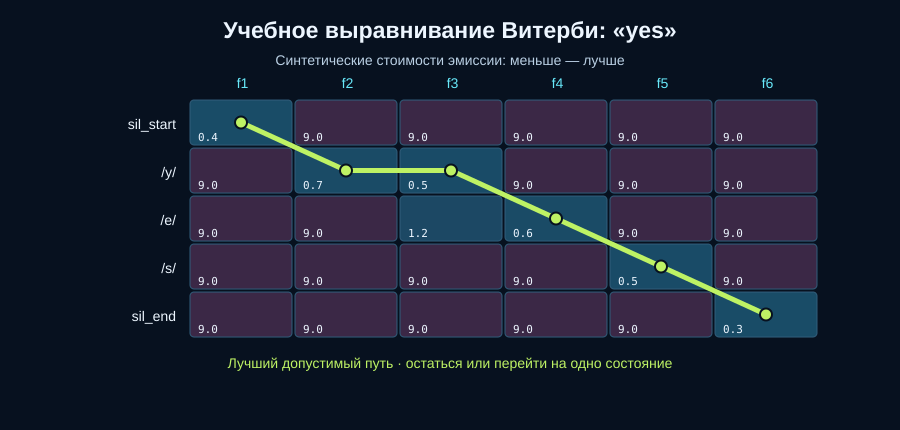

In [12]:
display(SVG(filename=str(OUT / "viterbi_trellis.svg")))

### Таблицы результатов

Читаю готовые CSV, чтобы сравнить их с расчётами выше, а не переносить значения вручную

In [ ]:
for filename in ["alignment_path.csv", "candidate_scores.csv"]:
    print("\n", filename)
    with (OUT / filename).open(encoding="utf-8", newline="") as file:
        for record in csv.DictReader(file):
            print(record)
            
summary = json.loads((OUT / "summary.json").read_text(encoding="utf-8"))
print("\nСводка:")
print(json.dumps(summary, indent=2, ensure_ascii=False))


 alignment_path.csv
{'frame': 'f1', 'state_index': '0', 'state_label': 'sil_start', 'emission_cost': '0.400', 'path_cost_so_far': '0.400'}
{'frame': 'f2', 'state_index': '1', 'state_label': '/y/', 'emission_cost': '0.700', 'path_cost_so_far': '1.100'}
{'frame': 'f3', 'state_index': '1', 'state_label': '/y/', 'emission_cost': '0.500', 'path_cost_so_far': '1.600'}
{'frame': 'f4', 'state_index': '2', 'state_label': '/e/', 'emission_cost': '0.600', 'path_cost_so_far': '2.200'}
{'frame': 'f5', 'state_index': '3', 'state_label': '/s/', 'emission_cost': '0.500', 'path_cost_so_far': '2.700'}
{'frame': 'f6', 'state_index': '4', 'state_label': 'sil_end', 'emission_cost': '0.300', 'path_cost_so_far': '3.000'}

 candidate_scores.csv
{'lm_weight': '0.00', 'rank': '1', 'candidate_id': 'acoustic_favorite', 'transcript': 'we drink strong coffee', 'acoustic_log_score': '-1.000000', 'lm_log_score': '-2.654739', 'combined_log_score': '-1.000000'}
{'lm_weight': '0.00', 'rank': '2', 'candidate_id': 'langu

## 6. Проверки граничных случаев

Проверяю не только известный ответ из примера, но и два свойства реализации: 
1.  сохранение состояния при равных накопленных стоимостях 
2.  обработку недопустимых входных данных

In [14]:
# На втором кадре оба пути к состоянию 1 равны по стоимости,
# поэтому выбирается переход из состояния 0 только если сохранение недоступно
tie_costs = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
tie_path, tie_cost = viterbi_align(tie_costs)
print("Путь при равных стоимостях:", tie_path, "стоимость:", tie_cost)
assert tie_path == [0, 1, 1]

try:
    viterbi_align([[0.1, 0.2]])
except ValueError as exc:
    print("Ожидаемая ошибка:", exc)
else:
    raise AssertionError("Ожидалась проверка недостатка кадров")

assert rank_candidates(candidates, weight=0)[0]["candidate_id"] == "acoustic_favorite"
assert rank_candidates(candidates, weight=0.5)[0]["candidate_id"] == "language_favorite"
print("Проверки пройдены")

Путь при равных стоимостях: [0, 1, 1] стоимость: 0.0
Ожидаемая ошибка: недостаточно кадров для перехода по всем состояниям
Проверки пройдены


## 7. Ответы на вопросы

### 1. Две ячейки с низкой стоимостью и одна с высокой

В матрице стоимость `f1 / sil_start` равна 0.4, а `f3 /y/` - 0.5. Это низкие стоимости, поэтому соответствующие клетки на карте темнее

Для сравнения, стоимость `f1 /e/` равна 9.0. Карта показывает локальные стоимости эмиссии, а не сумму стоимостей вдоль всего пути

### 2. Примеры переходов зелёного пути

Между `f2` и `f3` путь остаётся в `/y/`. Между `f3` и `f4` происходит переход `/y/ -> /e/`. Эти действия разрешены условиями задачи

### 3. Сравнение лучшего и альтернативного пути

Лучший путь имеет стоимость 3.0, альтернативный - 3.7. Разница составляет 0.7

У лучшего пути на кадре `f3` выбрано `/y/` со стоимостью 0.5, у альтернативного - `/e/` со стоимостью 1.2. Остальные выбранные состояния совпадают, поэтому разница в сумме целиком объясняется третьим кадром

### 4. Первые кандидаты при `λ=0` и `λ=0.5`

При `λ=0` побеждает `acoustic_favorite`: акустическая оценка -1.000000, языковая -2.654739, общая -1.000000

При `λ=0.5` побеждает `language_favorite`: акустическая оценка -1.200000, языковая -1.911720, общая -2.155860

### 5. Почему лидер меняется

Разница акустических оценок равна 0.2 в пользу `acoustic_favorite`, но LM предпочитает `language_favorite` с разницей примерно 0.743019

При `λ=0.5` языковое преимущество даёт около 0.371510 балла, чего достаточно, чтобы компенсировать акустическое отставание 0.2

## 8. Итог

В алгоритме Витерби получил путь `sil_start, /y/, /y/, /e/, /s/, sil_end` со стоимостью 3.0, что на 0.7 меньше альтернативного пути. Повторение `/y/` на двух соседних кадрах показывает разрешённый переход с сохранением состояния

Биграммная модель обучена на семи предложениях, словарь содержит 10 предсказываемых токенов. Для пары `drink green` при сглаживании `k=0.5` вероятность составила около 0.388889

При нулевом весе LM выигрывает `we drink strong coffee`, но при весе 0.5 выигрывает `we drink green tea`. На этом учебном примере видно, что добавление языковой оценки может изменить порядок гипотез
